# 02 · LMS step size and number of taps

The paper uses LMS with "default parameters in MATLAB" (`dsp.LMSFilter`: step size 0.1, 32 taps).
On the MIT-BIH / NSTDB signals this setting diverges, so step size × taps is swept here.
**One setting** is then used for every LMS filter in every method and experiment, as in the paper.

Sweep: the paper's records (Fig. 8 records for BW+PLI with EMD, Fig. 10 records for the four methods) at SNRin = −5 dB (largest noise) and 10 dB.
Chosen setting: stable (finite output) on every run, then the highest mean SNRimp over all runs and methods.

In [3]:
from pathlib import Path
import sys, json

project_root = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

RESULTS = project_root / "results"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
METHOD_COLORS = {"PEAF": "#1f3b73", "SEAF": "#9aa83a", "PDAF": "#d62728", "SDAF": "#3cb9a0"}


In [4]:
sweep = pd.read_csv(RESULTS / "lms_sweep.csv")
setting = json.loads((RESULTS / "lms_setting.json").read_text())
print("chosen setting:", setting)
MUS = sorted(sweep.mu.unique(), reverse=True); TAPS = sorted(sweep.taps.unique())

def grid(df):
    g = df.groupby(["mu", "taps"]).SNRimp_dB
    mean = g.mean().unstack().reindex(index=MUS, columns=TAPS)
    ok = g.apply(lambda v: np.isfinite(v).all()).unstack().reindex(index=MUS, columns=TAPS)
    return mean, ok

def heat(ax, mean, ok, title):
    shown = mean.where(ok)
    im = ax.imshow(shown.clip(lower=-10).values, cmap="viridis", aspect="auto")
    for i, mu in enumerate(MUS):
        for j, L in enumerate(TAPS):
            txt = "diverged" if not ok.loc[mu, L] else f"{mean.loc[mu, L]:.1f}"
            ax.text(j, i, txt, ha="center", va="center", fontsize=8,
                    color="w" if not ok.loc[mu, L] or mean.loc[mu, L] < shown.max().max() - 3 else "k")
    ax.set_xticks(range(len(TAPS)), TAPS); ax.set_yticks(range(len(MUS)), [f"{m:g}" for m in MUS])
    ax.set_xlabel("taps"); ax.set_ylabel("step size μ"); ax.set_title(title, fontsize=10)
    ax.add_patch(plt.Rectangle((TAPS.index(32) - .5, MUS.index(0.1) - .5), 1, 1, fill=False, ec="red", lw=2))
    ax.add_patch(plt.Rectangle((TAPS.index(setting["taps"]) - .5, MUS.index(setting["mu"]) - .5), 1, 1,
                               fill=False, ec="orange", lw=2.5, ls="--"))
    ax.grid(False)
    return im

chosen setting: {'mu': 0.0001, 'taps': 16}


## Mean SNRimp over all runs (red box: MATLAB default, orange dashed: chosen)

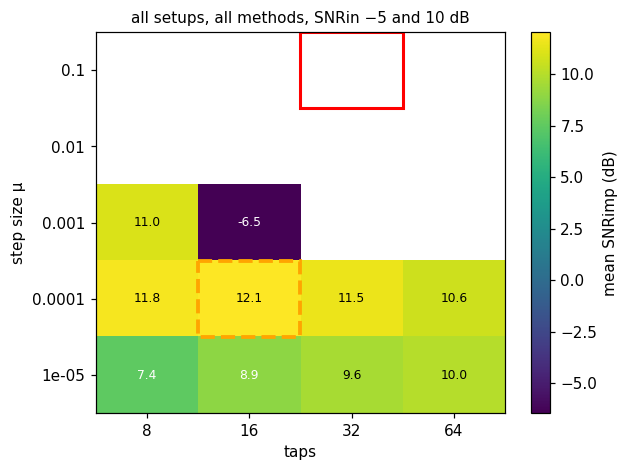

In [5]:
fig, ax = plt.subplots(figsize=(6, 4.5))
mean, ok = grid(sweep)
plt.colorbar(heat(ax, mean, ok, "all setups, all methods, SNRin −5 and 10 dB"), label="mean SNRimp (dB)")
plt.show()

## Per method and SNRin

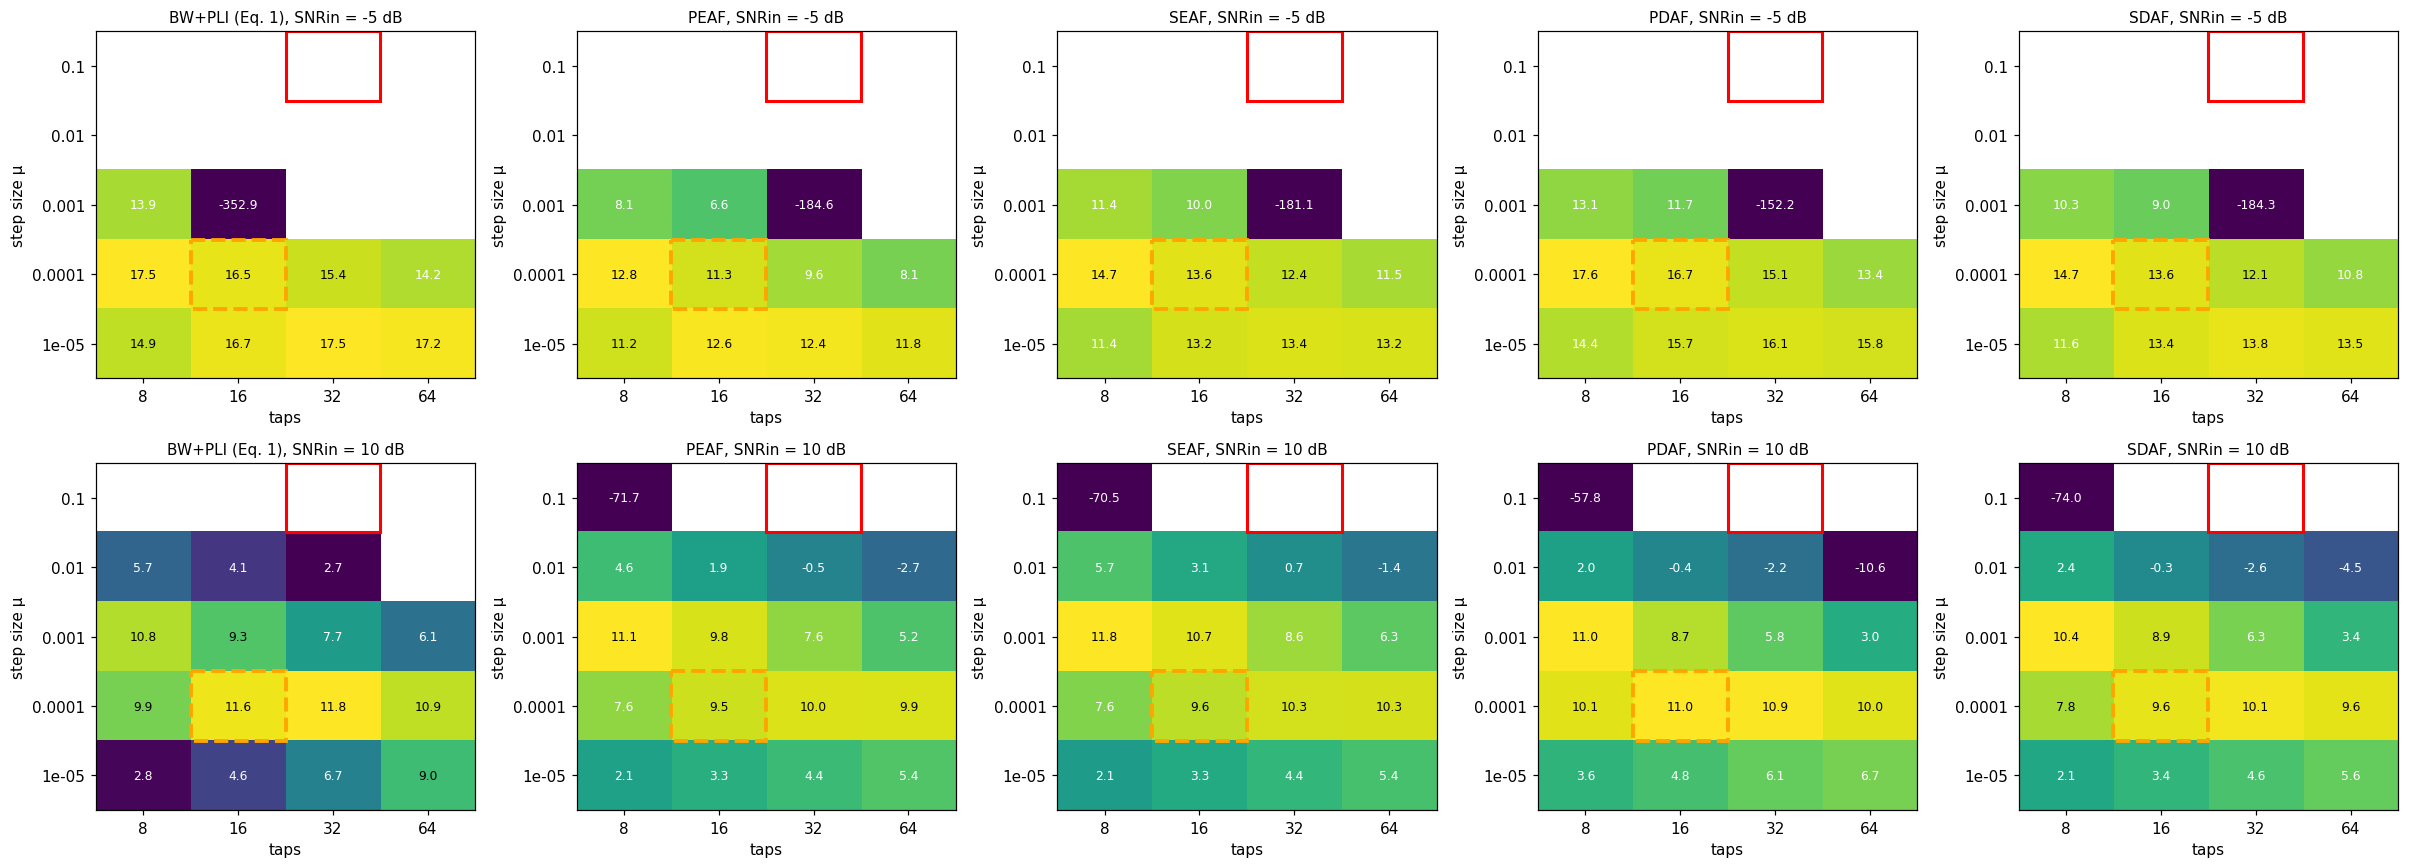

In [6]:
methods = ["EMD+LMS", "PEAF", "SEAF", "PDAF", "SDAF"]
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for col, m in enumerate(methods):
    for row, snr in enumerate([-5, 10]):
        mean, ok = grid(sweep[(sweep.method == m) & (sweep.SNRin_dB == snr)])
        label = "BW+PLI (Eq. 1)" if m == "EMD+LMS" else m
        heat(axes[row, col], mean, ok, f"{label}, SNRin = {snr} dB")
plt.tight_layout(); plt.show()

## SNRimp vs step size (taps fixed at the chosen value)

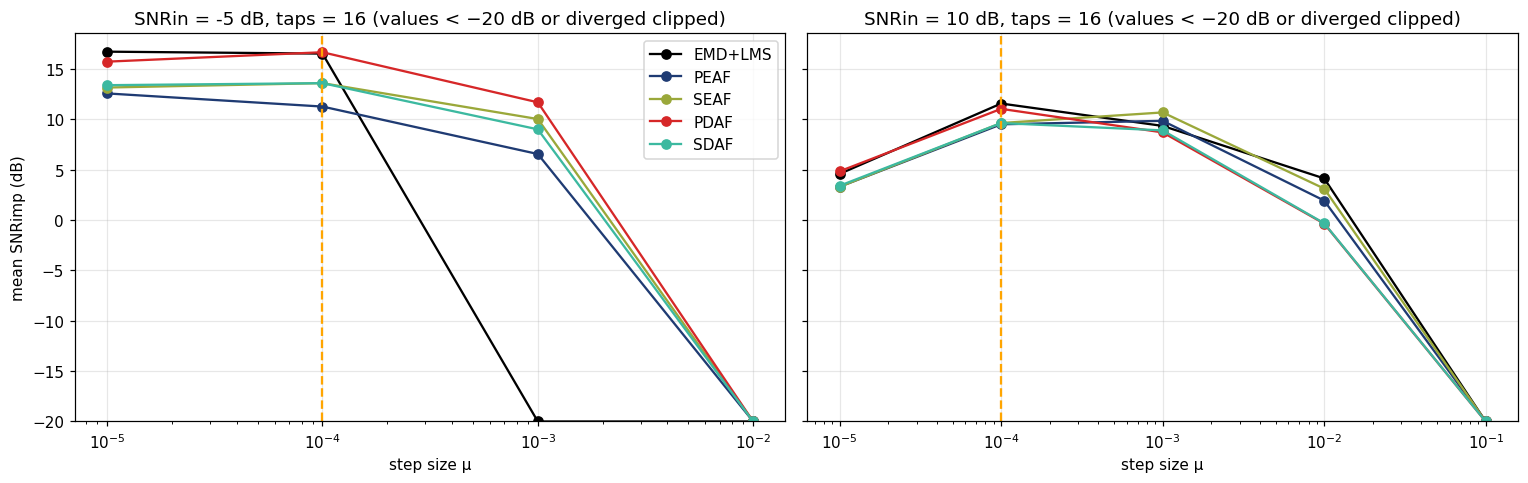

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, snr in zip(axes, [-5, 10]):
    d = sweep[(sweep.SNRin_dB == snr) & (sweep.taps == setting["taps"])]
    for m in methods:
        v = d[d.method == m].groupby("mu").SNRimp_dB.mean().reindex(MUS)
        ax.semilogx(v.index, v.clip(lower=-20).values, "o-", label=m, color=METHOD_COLORS.get(m, "k"))
    ax.axvline(setting["mu"], color="orange", ls="--"); ax.set_ylim(-20, None)
    ax.set_xlabel("step size μ"); ax.set_title(f"SNRin = {snr} dB, taps = {setting['taps']} (values < −20 dB or diverged clipped)")
axes[0].set_ylabel("mean SNRimp (dB)"); axes[0].legend()
plt.tight_layout(); plt.show()

## Table: mean SNRimp per setting (NaN = diverged on at least one run)

In [8]:
mean, ok = grid(sweep)
mean.where(ok).round(2)

taps,8,16,32,64
mu,,,,
0.10000,NaN,NaN,NaN,NaN
0.01000,NaN,NaN,NaN,NaN
0.00100,11.01,-6.47,NaN,NaN
0.00010,11.81,12.05,11.53,10.64
0.00001,7.44,8.88,9.64,9.98
